# Session 6: Regular Expressions and Tokenization

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in ['access_sample.log']:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-06_regex_basics.py`

In [2]:
"""
Session 6 · Example 1: the building blocks of regular expressions
-----------------------------------------------------------------
Each line shows a pattern, a test string and every match re.findall finds.
Run:  python session-06_regex_basics.py
"""
import re

def show(pattern, text, note=""):
    found = re.findall(pattern, text)
    print(f"  {pattern:<22} on {text!r:<38} -> {found}  {note}")

print("Literal characters and the dot")
show(r"cat", "cat, concat, Cat")
show(r"c.t", "cat cot c9t ct", ". = any char except newline")

print("Character classes [...]")
show(r"[aeiou]", "Karachi", "any one vowel")
show(r"[A-Z]", "Diploma in AI", "any capital")
show(r"[^0-9 ]", "Room 204 B", "^ inside [] = NOT")
show(r"[0-9a-fA-F]+", "colour #FF6B1A and #fcd34d", "hex digits")

print("Special sequences")
show(r"\d+", "Order 66 costs Rs 1450", "\\d digit")
show(r"\w+", "hello_world, 2026!", "\\w letter/digit/_")
show(r"\s", "a b\tc", "\\s whitespace")
show(r"\bin\b", "in inside within in", "\\b word boundary")
show(r"\D+", "03001234567 ext", "\\D NON-digit")

print("Quantifiers")
show(r"colou?r", "color colour colouur", "? = 0 or 1")
show(r"go*gle", "ggle gogle google", "* = 0 or more")
show(r"go+gle", "ggle gogle google", "+ = 1 or more")
show(r"\d{4}", "PIN 1234, year 2026, 99", "{n} exactly n")
show(r"\d{2,3}", "7 42 314 2718", "{m,n} between m and n")

print("Anchors")
show(r"^Hello", "Hello world. Hello again")
show(r"again$", "Hello world. Hello again")

print("Alternation and groups")
show(r"cat|dog", "cat dog cow")
show(r"(\d+)-(\d+)", "pages 10-15 and 20-24", "groups -> tuples")
show(r"(?:Mr|Ms|Dr)\.? \w+", "Dr. Ali met Ms Sana and Mr Khan", "(?:) non-capturing")

print("Greedy vs lazy")
html = "<b>bold</b> and <i>italic</i>"
show(r"<.+>", html, "greedy grabs as much as possible")
show(r"<.+?>", html, "lazy +? stops early")

print("Escaping metacharacters . ^ $ * + ? { } [ ] \\ | ( )")
show(r"\$\d+\.\d{2}", "price $19.99 or $5.50")
print("  re.escape('1+1=2?') ->", re.escape("1+1=2?"))
print("Raw strings: len('\\n') =", len("\n"), "but len(r'\\n') =", len(r"\n"))

Literal characters and the dot
  cat                    on 'cat, concat, Cat'                     -> ['cat', 'cat']  
  c.t                    on 'cat cot c9t ct'                       -> ['cat', 'cot', 'c9t']  . = any char except newline
Character classes [...]
  [aeiou]                on 'Karachi'                              -> ['a', 'a', 'i']  any one vowel
  [A-Z]                  on 'Diploma in AI'                        -> ['D', 'A', 'I']  any capital
  [^0-9 ]                on 'Room 204 B'                           -> ['R', 'o', 'o', 'm', 'B']  ^ inside [] = NOT
  [0-9a-fA-F]+           on 'colour #FF6B1A and #fcd34d'           -> ['c', 'FF6B1A', 'a', 'd', 'fcd34d']  hex digits
Special sequences
  \d+                    on 'Order 66 costs Rs 1450'               -> ['66', '1450']  \d digit
  \w+                    on 'hello_world, 2026!'                   -> ['hello_world', '2026']  \w letter/digit/_
  \s                     on 'a b\tc'                               -> [' ', '\

## Example: `session-06_re_methods.py`

In [3]:
"""
Session 6 · Example 2: the methods of the re module
---------------------------------------------------
Run:  python session-06_re_methods.py
"""
import re

text = "Invoice INV-2026-0042 issued 2026-10-05 to ali.khan@example.com for Rs 12,500. " \
       "Reminder sent 2026-10-20 to accounts@uni.edu.pk."

# match: only at the START of the string
print("match('Invoice'):", re.match(r"Invoice", text))
print("match('INV'):", re.match(r"INV", text))

# search: first match ANYWHERE; returns a Match object (or None)
m = re.search(r"INV-(\d{4})-(\d{4})", text)
print("search ->", m.group(), "| year:", m.group(1), "| number:", m.group(2), "| span:", m.span())

# Named groups make code self-documenting
m = re.search(r"(?P<year>\d{4})-(?P<month>\d{2})-(?P<day>\d{2})", text)
print("named groups:", m.groupdict())

# findall: list of all matches (strings, or tuples when there are groups)
print("findall dates:", re.findall(r"\d{4}-\d{2}-\d{2}", text))
print("findall emails:", re.findall(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+", text))

# finditer: Match objects one by one, with positions
for mm in re.finditer(r"\d{4}-\d{2}-\d{2}", text):
    print(f"  date {mm.group()} at characters {mm.start()}-{mm.end()}")

# sub: replace; the replacement can use groups or be a function
masked = re.sub(r"[\w.+-]+@([\w-]+(?:\.[\w-]+)+)", r"***@\1", text)
print("sub mask emails:", re.findall(r"\*\*\*@[\w.-]*\w", masked))
print("sub reorder dates:", re.sub(r"(\d{4})-(\d{2})-(\d{2})", r"\3/\2/\1", "due 2026-10-05"))
def to_dollars(mo):
    rupees = int(mo.group(1).replace(",", ""))
    return f"${rupees / 280:.2f}"                   # illustrative exchange rate
print("sub with a function:", re.sub(r"Rs ([\d,]+)", to_dollars, "Fee Rs 12,500 and Rs 700"))
print("subn counts replacements:", re.subn(r"\s+", " ", "too    many   spaces"))

# split on a pattern (several delimiters at once)
print("split:", re.split(r"[;,|]\s*", "python, sql;git | flask"))
print("split keeping delimiters:", re.split(r"([.!?])", "Hi! How are you? Fine."))

# compile once, reuse many times (faster and cleaner in loops)
phone = re.compile(r"^03\d{2}-?\d{7}$")
for p in ["0300-1234567", "03001234567", "021-1234567", "0300-123456"]:
    print(f"  {p:<14} valid mobile? {bool(phone.match(p))}")

# fullmatch: the WHOLE string must match (great for validation)
print("fullmatch roll:", bool(re.fullmatch(r"AI-\d{4}-\d{4}", "AI-2026-0147")),
      bool(re.fullmatch(r"AI-\d{4}-\d{4}", "AI-2026-0147x")))

# Flags
print("IGNORECASE:", re.findall(r"python", "Python PYTHON python", flags=re.I))
print("MULTILINE ^:", re.findall(r"^\w+", "first line\nsecond line", flags=re.M))
verbose = re.compile(r"""
    (?P<user>[\w.]+)      # user name
    @
    (?P<domain>[\w.]+)    # domain
""", re.VERBOSE)
print("VERBOSE:", verbose.search("write to hamna.k@example.org").groupdict())

# Lookahead: password must contain a digit and a capital, 8+ chars
strong = re.compile(r"^(?=.*\d)(?=.*[A-Z]).{8,}$")
for pw in ["karachi2026", "Karachi2026", "Ka1"]:
    print(f"  {pw:<12} strong? {bool(strong.match(pw))}")

match('Invoice'): <re.Match object; span=(0, 7), match='Invoice'>
match('INV'): None
search -> INV-2026-0042 | year: 2026 | number: 0042 | span: (8, 21)
named groups: {'year': '2026', 'month': '10', 'day': '05'}
findall dates: ['2026-10-05', '2026-10-20']
findall emails: ['ali.khan@example.com', 'accounts@uni.edu.pk']
  date 2026-10-05 at characters 29-39
  date 2026-10-20 at characters 93-103
sub mask emails: ['***@example.com', '***@uni.edu.pk']
sub reorder dates: due 05/10/2026
sub with a function: Fee $44.64 and $2.50
subn counts replacements: ('too many spaces', 2)
split: ['python', 'sql', 'git ', 'flask']
split keeping delimiters: ['Hi', '!', ' How are you', '?', ' Fine', '.', '']
  0300-1234567   valid mobile? True
  03001234567    valid mobile? True
  021-1234567    valid mobile? False
  0300-123456    valid mobile? False
fullmatch roll: True False
IGNORECASE: ['Python', 'PYTHON', 'python']
MULTILINE ^: ['first', 'second']
VERBOSE: {'user': 'hamna.k', 'domain': 'example.org'}
 

## Example: `session-06_tokenization.py`

In [4]:
"""
Session 6 · Example 3: tokenizing text with regular expressions
---------------------------------------------------------------
Tokenization = splitting text into units (sentences, words, symbols) that a
program or an NLP model can count and analyse. No external library needed.
Run:  python session-06_tokenization.py
"""
import re
from collections import Counter

review = ("Loved the new campus café!!! The chai is great, but Wi-Fi isn't. "
          "Prices went up 15% since Sept... Dr. Khan's AI lab opens at 9:30 a.m. "
          "#KarachiEats @campus_cafe https://example.com/menu :)")

# 1. Naive split breaks on punctuation
print("str.split():", review.split()[:8])

# 2. Sentence tokenization: split after . ! ? followed by space + capital,
#    but protect common abbreviations first
protected = re.sub(r"\b(Dr|Mr|Ms|Mrs|a\.m|p\.m)\.", lambda m: m.group(0).replace(".", "<DOT>"), review)
sentences = [s.replace("<DOT>", ".") for s in re.split(r"(?<=[.!?])\s+(?=[A-Z#@])", protected)]
print("\nSentences:")
for i, s in enumerate(sentences, 1):
    print(f"  {i}. {s}")

# 3. Word tokenization with a pattern that knows about real-world tokens
TOKEN = re.compile(r"""
    https?://\S+              # URLs
  | [#@]\w+                   # hashtags and mentions
  | (?:Dr|Mr|Ms|Mrs)\.        # titles keep their dot
  | (?:[A-Za-z]\.){2,}        # abbreviations like a.m.
  | \.{3}                     # an ellipsis is one token
  | \d+(?::\d+)?%?            # numbers, times like 9:30, percentages
  | \w+(?:[-']\w+)*           # words, incl. Wi-Fi and isn't
  | [:;]-?[)(DP]              # simple emoticons
  | [^\w\s]                   # any other single symbol
""", re.VERBOSE)
tokens = TOKEN.findall(review)
print("\nTokens:", tokens)
print("token count:", len(tokens))

# 4. Classify tokens by type
def kind(tok):
    if tok.startswith("http"): return "url"
    if tok[0] in "#@": return "tag"
    if tok.endswith(".") and tok[0].isalpha(): return "abbreviation"
    if tok[0].isdigit(): return "number"
    if re.fullmatch(r"\w+(?:[-']\w+)*", tok): return "word"
    return "symbol"
print("types:", dict(Counter(kind(t) for t in tokens)))

# 5. Normalise words: lower-case, drop stop words, count
STOP = {"the", "is", "but", "at", "since", "s", "a", "m", "up"}
words = [t.lower() for t in tokens if kind(t) == "word"]
content = [w for w in words if w not in STOP]
print("content words:", content)

# 6. Word frequencies across several reviews + a chart
reviews = [review,
           "The chai is cheap and the samosa is great. Great service!",
           "Wi-Fi is slow, chai is cold, prices are high.",
           "Great lab, great teachers, great chai."]
freq = Counter(w.lower() for r in reviews for w in re.findall(r"\w+(?:[-']\w+)*", r)
               if w.lower() not in STOP | {"and", "are", "isn't", "new", "went", "opens"})
top = freq.most_common(8)
print("\nTop words in 4 reviews:", top)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
labels, counts = zip(*top)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(labels, counts, color="#FF6B1A")
ax.set_ylabel("count"); ax.set_title("Most frequent content words after regex tokenization")
fig.tight_layout(); fig.savefig("session-06_tokenization.png", dpi=110)
print("Chart saved: session-06_tokenization.png")

str.split(): ['Loved', 'the', 'new', 'campus', 'café!!!', 'The', 'chai', 'is']

Sentences:
  1. Loved the new campus café!!!
  2. The chai is great, but Wi-Fi isn't.
  3. Prices went up 15% since Sept...
  4. Dr. Khan's AI lab opens at 9:30 a.m. #KarachiEats @campus_cafe https://example.com/menu :)

Tokens: ['Loved', 'the', 'new', 'campus', 'café', '!', '!', '!', 'The', 'chai', 'is', 'great', ',', 'but', 'Wi-Fi', "isn't", '.', 'Prices', 'went', 'up', '15%', 'since', 'Sept', '...', 'Dr.', "Khan's", 'AI', 'lab', 'opens', 'at', '9:30', 'a.m.', '#KarachiEats', '@campus_cafe', 'https://example.com/menu', ':)']
token count: 36
types: {'word': 22, 'symbol': 7, 'number': 2, 'abbreviation': 2, 'tag': 2, 'url': 1}
content words: ['loved', 'new', 'campus', 'café', 'chai', 'great', 'wi-fi', "isn't", 'prices', 'went', 'sept', "khan's", 'ai', 'lab', 'opens']

Top words in 4 reviews: [('great', 6), ('chai', 4), ('wi-fi', 2), ('prices', 2), ('lab', 2), ('loved', 1), ('campus', 1), ('café', 1)]


Chart saved: session-06_tokenization.png


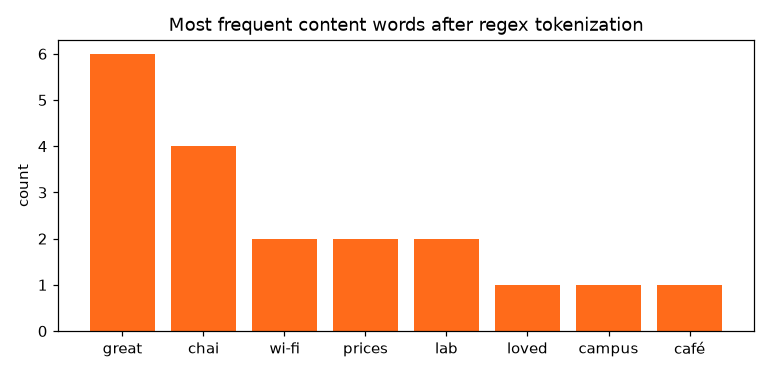

In [5]:
from IPython.display import Image, display
display(Image(filename='session-06_tokenization.png'))  # chart saved by the cell above

## Example: `session-06_problem_form_validator.py`

In [6]:
"""
Session 6 · Real-life problem: validating and extracting admission-form data
----------------------------------------------------------------------------
PROBLEM
An admissions office receives (a) structured form fields that must be
VALIDATED, and (b) free-text emails from which details must be EXTRACTED.
Rules (formats used in Pakistan):
  CNIC    : 5 digits - 7 digits - 1 digit        e.g. 42101-1234567-1
  Mobile  : 03XX-XXXXXXX or 03XXXXXXXXX or +923XXXXXXXXX
  Email   : name@domain.tld
  Roll no : AI-YYYY-NNNN with year 2020-2029
  DOB     : DD/MM/YYYY
Write one compiled pattern per rule, validate a batch of applicants, normalise
phone numbers to +92 format, and extract every phone/email/CNIC from emails.
Run:  python session-06_problem_form_validator.py
"""
import re

RULES = {
    "cnic":   re.compile(r"\d{5}-\d{7}-\d"),
    "mobile": re.compile(r"(?:\+92|0)3\d{2}-?\d{7}"),
    "email":  re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)*\.[A-Za-z]{2,}"),
    "roll":   re.compile(r"AI-202\d-\d{4}"),
    "dob":    re.compile(r"(0[1-9]|[12]\d|3[01])/(0[1-9]|1[0-2])/(19|20)\d{2}"),
}

def validate(applicant):
    """Return a list of field names that FAIL their rule (fullmatch = whole value)."""
    return [field for field, rx in RULES.items() if not rx.fullmatch(applicant.get(field, "").strip())]

def normalise_mobile(raw):
    """0300-1234567 / 03001234567 / +923001234567  ->  +923001234567"""
    if not RULES["mobile"].fullmatch(raw.strip()):
        return None                                   # never 'fix' an invalid number
    digits = re.sub(r"\D", "", raw)                  # keep digits only
    return "+92" + digits[-10:]

applicants = [
    {"name": "Ayesha Siddiqui", "cnic": "42101-1234567-2", "mobile": "0321-7654321",
     "email": "ayesha.s@example.com", "roll": "AI-2026-0001", "dob": "14/12/2004"},
    {"name": "Omar Farooq", "cnic": "4210112345672", "mobile": "+923001112233",
     "email": "omar@mail", "roll": "AI-2026-0002", "dob": "31/02/2005"},
    {"name": "Mehwish Ali", "cnic": "35202-7654321-8", "mobile": "021-34567890",
     "email": "mehwish_ali@uni.edu.pk", "roll": "AI-2019-0003", "dob": "05/13/2003"},
    {"name": "Danish Raza", "cnic": "61101-2223334-5", "mobile": "03451234567",
     "email": "danish.raza+admission@example.org", "roll": "AI-2026-0004", "dob": "01/01/2006"},
]
print("Validation")
for a in applicants:
    bad = validate(a)
    status = "OK" if not bad else "fix: " + ", ".join(bad)
    print(f"  {a['name']:<16} {status:<26} phone -> {normalise_mobile(a['mobile'])}")
print("  note: 31/02/2005 passes the PATTERN; regex checks format, not calendar logic.")
print("        use datetime.strptime for real date validation (Session 5).")

emails = """
From: parent.khan@example.com
Assalam-o-Alaikum, my son's CNIC is 42201-9876543-1 and you can call me on
0333-4445566 or my wife on +923214445566. His friend (CNIC 42101-1112223-3)
also applied; reach him at friend_99@uni.edu.pk. Wrong number 12345-678 ignore.
"""
print("\nExtraction from free text")
for field in ("cnic", "mobile", "email"):
    print(f"  {field:<7}", RULES[field].findall(emails))

masked = RULES["cnic"].sub(lambda m: m.group()[:5] + "-*******-" + m.group()[-1], emails)
print("\nPrivacy-masked text:")
print(masked.strip())

Validation
  Ayesha Siddiqui  OK                         phone -> +923217654321
  Omar Farooq      fix: cnic, email           phone -> +923001112233
  Mehwish Ali      fix: mobile, roll, dob     phone -> None
  Danish Raza      OK                         phone -> +923451234567
  note: 31/02/2005 passes the PATTERN; regex checks format, not calendar logic.
        use datetime.strptime for real date validation (Session 5).

Extraction from free text
  cnic    ['42201-9876543-1', '42101-1112223-3']
  mobile  ['0333-4445566', '+923214445566']
  email   ['parent.khan@example.com', 'friend_99@uni.edu.pk']

Privacy-masked text:
From: parent.khan@example.com
Assalam-o-Alaikum, my son's CNIC is 42201-*******-1 and you can call me on
0333-4445566 or my wife on +923214445566. His friend (CNIC 42101-*******-3)
also applied; reach him at friend_99@uni.edu.pk. Wrong number 12345-678 ignore.


## Example: `session-06_project_log_analyzer.py`

In [7]:
"""
Session 6 · Mini project: web-server log analyzer
-------------------------------------------------
Web servers write one line per request in the "combined log format":
  IP - - [day/Mon/year:hh:mm:ss zone] "METHOD /path HTTP/1.1" status bytes "referrer" "agent"
This project parses access_sample.log with ONE verbose regex using named
groups, then reports traffic per hour, status codes, top pages, and flags
IPs with repeated failed logins (a simple security check).
Run:  python session-06_project_log_analyzer.py
"""
import re
from collections import Counter, defaultdict

LINE = re.compile(r"""
    ^(?P<ip>\d{1,3}(?:\.\d{1,3}){3})        # client IP address
    \s-\s-\s
    \[(?P<day>\d{2})/(?P<mon>\w{3})/(?P<year>\d{4}):(?P<hour>\d{2}):\d{2}:\d{2}\s[+-]\d{4}\]
    \s"(?P<method>[A-Z]+)\s(?P<path>\S+)\sHTTP/[\d.]+"
    \s(?P<status>\d{3})\s(?P<size>\d+|-)
    \s"[^"]*"\s"(?P<agent>[^"]*)"$
""", re.VERBOSE)

records, rejected = [], []
with open("access_sample.log", encoding="utf-8") as f:
    for n, line in enumerate(f, 1):
        m = LINE.match(line.strip())
        if m:
            records.append(m.groupdict())
        else:
            rejected.append(n)

print(f"parsed {len(records)} requests, could not parse line(s) {rejected}")
print("first record:", records[0])

status = Counter(r["status"] for r in records)
print("\nstatus codes:", dict(sorted(status.items())))
errors = sum(c for s, c in status.items() if s[0] in "45")
print(f"error rate: {errors / len(records):.0%}")

pages = Counter(re.sub(r"\?.*", "", r["path"]) for r in records if r["method"] == "GET")
print("top pages:", pages.most_common(3))

total_bytes = sum(int(r["size"]) for r in records if r["size"] != "-")
print(f"data served: {total_bytes / 1024:.1f} KB")

failed = defaultdict(int)
for r in records:
    if r["path"] == "/login" and r["status"] == "401":
        failed[r["ip"]] += 1
agent_of = {r["ip"]: r["agent"] for r in records}       # last agent seen per IP
for ip, count in failed.items():
    if count >= 3:
        print(f"SECURITY: {ip} had {count} failed logins (agent {agent_of[ip]})")

hours = Counter(int(r["hour"]) for r in records)
print("requests per hour:", dict(sorted(hours.items())))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
hs = list(range(9, 15))
a1.bar([f"{h}:00" for h in hs], [hours.get(h, 0) for h in hs], color="#FF6B1A")
a1.set_title("Requests per hour"); a1.tick_params(axis="x", rotation=45)
codes = sorted(status)
colours = {"2": "#FF6B1A", "3": "#FCD34D", "4": "#F43F5E", "5": "#A78BFA"}
a2.bar(codes, [status[c] for c in codes], color=[colours[c[0]] for c in codes])
a2.set_title("Responses by status code")
fig.tight_layout(); fig.savefig("session-06_project_log_analyzer.png", dpi=110)
print("Chart saved: session-06_project_log_analyzer.png")

parsed 19 requests, could not parse line(s) [12]
first record: {'ip': '192.168.1.10', 'day': '20', 'mon': 'Oct', 'year': '2026', 'hour': '09', 'method': 'GET', 'path': '/index.html', 'status': '200', 'size': '5120', 'agent': 'Mozilla/5.0'}

status codes: {'200': 11, '304': 1, '401': 4, '404': 2, '500': 1}
error rate: 37%
top pages: [('/courses/ai', 4), ('/index.html', 3), ('/old-page', 2)]
data served: 70.2 KB
SECURITY: 10.0.0.5 had 4 failed logins (agent curl/8.0)
requests per hour: {9: 6, 10: 3, 11: 3, 12: 3, 13: 2, 14: 2}
Chart saved: session-06_project_log_analyzer.png


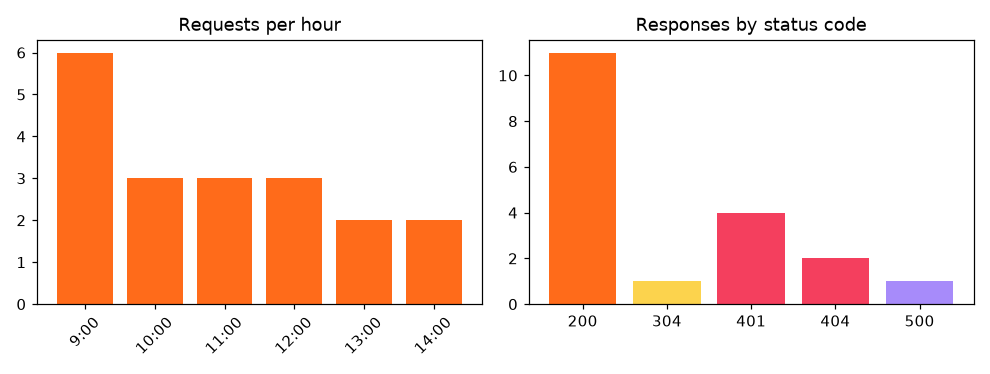

In [8]:
from IPython.display import Image, display
display(Image(filename='session-06_project_log_analyzer.png'))  # chart saved by the cell above